# Load data: ICEWS

We are going to use the following libraries:

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
from scipy.sparse import coo_matrix, save_npz
from scipy.stats import rankdata, norm
import os
import json

We load the data from a `parquet` file and display some statistics.

In [2]:
path = r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\python\others\Hoff_2015_MultilinearTensorRegression\ICEWS_month_1995_2022_242c.parquet"
tensornetwork = pd.read_parquet(path)
tensornetwork["month"] = pd.to_datetime(tensornetwork["month"])
display(tensornetwork.head())
print(tensornetwork.shape)
print(tensornetwork.info())

,month,origin,destination,layer,weight
0,1994-12-01,Bangladesh,Bangladesh,Verbal-,1
1,1994-12-01,Barbados,Barbados,Material-,1
2,1994-12-01,Bosnia and Herzegovina,Serbia,Verbal+,1
3,1994-12-01,Canada,Canada,Material-,1
4,1994-12-01,Canada,Canada,Verbal+,1


(1437951, 5)
<class 'pandas.DataFrame'>
RangeIndex: 1437951 entries, 0 to 1437950
Data columns (total 5 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   month        1437951 non-null  datetime64[us]
 1   origin       1437951 non-null  str           
 2   destination  1437951 non-null  str           
 3   layer        1437951 non-null  str           
 4   weight       1437951 non-null  int32         
dtypes: datetime64[us](1), int32(1), str(3)
memory usage: 83.4 MB
None


We construct the adjacency matrices for all 242 countries and save them.

In [3]:
tensornetwork = tensornetwork[(tensornetwork["month"] >= "1995-01-01") & (tensornetwork["month"] <= "2022-12-01")].copy()
countries = sorted(set(tensornetwork["origin"]) | set(tensornetwork["destination"]))
months = pd.date_range(start="1995-01-01", end="2022-12-01", freq="MS")
layers = ["Material-", "Material+", "Verbal-", "Verbal+"]
index_countries = {c: i for i, c in enumerate(countries)}
index_months = {m: i for i, m in enumerate(months)}
index_layers = {l: i for i, l in enumerate(layers)}
N = len(countries)
T = len(months)
K = len(layers)
tensornetwork["i"] = tensornetwork["origin"].map(index_countries)
tensornetwork["j"] = tensornetwork["destination"].map(index_countries)
tensornetwork["t"] = tensornetwork["month"].map(index_months)
tensornetwork["k"] = tensornetwork["layer"].map(index_layers)
missing_indexes = tensornetwork[["i", "j", "t", "k"]].isna().sum()
print("Missing indexes:")
print(missing_indexes)
assert tensornetwork[["i", "j", "t", "k"]].notna().all().all()
tensornetwork[["i", "j", "t", "k"]] = tensornetwork[["i", "j", "t", "k"]].astype(int)
matrices = {}
for k, layer in enumerate(layers):
    for t, month in enumerate(months):
        data = tensornetwork[(tensornetwork["k"] == k) &(tensornetwork["t"] == t)]
        A = coo_matrix((data["weight"].to_numpy(), (data["i"].to_numpy(), data["j"].to_numpy())),shape=(N, N),dtype=np.int64).tocsr()
        matrices[(k, t)] = A
    print("Finalized layer:", layer)
matrices_serie = {}
for (k, t), A in matrices.items():
    matrices_serie[f"A_{k}_{t}"] = A
np.savez_compressed("ICEWS_month_matrices_242_c.npz", **matrices_serie)
metadata = {"countries": countries, "months": months.strftime("%Y-%m-%d").tolist(), "layers": layers}
with open("ICEWS_month_metadata_242c.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)
print("\nCountries:", N)
print("Months:", T)
print("Layers:", K)
print("Matrices:", len(matrices))
print("Total possible matrices:", T * K)

Missing indexes:
i    0
j    0
t    0
k    0
dtype: int64
Finalized layer: Material-
Finalized layer: Material+
Finalized layer: Verbal-
Finalized layer: Verbal+

Countries: 252
Months: 336
Layers: 4
Matrices: 1344
Total possible matrices: 1344


We consult a particular matrix.

Dimensions: (252, 252)
Connections: 3646
Events: 47615


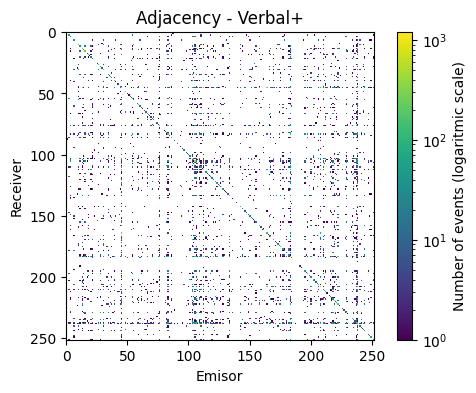

In [4]:

A = matrices[(3, 105)]
print("Dimensions:", A.shape)
print("Connections:", A.nnz)
print("Events:", A.sum())
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
plt.figure(figsize=(6, 4))
plt.imshow(A.toarray(), cmap="viridis", norm=LogNorm(vmin=1, vmax=A.toarray().max()), interpolation="nearest")
plt.colorbar(label="Number of events (logaritmic scale)")
plt.title("Adjacency - Verbal+")
plt.xlabel("Emisor")
plt.ylabel("Receiver")

plt.show()

Now, using a network aggregated over time and across layers, we evaluate the importance of each node by means of the PageRank metric.

In [5]:

aggnetwork = tensornetwork.groupby(["origin", "destination"],as_index=False)["weight"].sum()
aggnetwork = aggnetwork[aggnetwork["origin"] != aggnetwork["destination"]]
G = nx.from_pandas_edgelist(aggnetwork,source="origin",target="destination",edge_attr="weight",create_using=nx.DiGraph())
pagerank = nx.pagerank(G,alpha=0.85,weight="weight")
importance = pd.DataFrame({"country": list(pagerank.keys()), "pagerank": list(pagerank.values())})
importance = importance.sort_values("pagerank",ascending=False).reset_index(drop=True)
importance.index = importance.index + 1
importance.index.name = "ranking"
display(importance.head(50))

,country,pagerank
ranking,,
1,United States,0.100594
2,Russian Federation,0.051657
3,China,0.047604
4,Israel,0.024905
5,United Kingdom,0.024622
6,Japan,0.023751
7,Iran,0.022207
8,India,0.021972
9,France,0.020567


Following the methodology of Hoff (2015), and with the goal of reducing the number of null events, we select the L most relevant nodes for the multilayer dynamic network.

In [6]:
values_L = [10, 25, 30, 50, 75, 100, 242]
results_L = []
total_weight = tensornetwork["weight"].sum()
original_by_layer = tensornetwork.groupby("layer")["weight"].sum()
T = tensornetwork["month"].nunique()
K = len(layers)
for L in values_L:
    top_countries = set(importance.head(L)["country"])
    Lnetwork = tensornetwork[tensornetwork["origin"].isin(top_countries) & tensornetwork["destination"].isin(top_countries)]
    events = Lnetwork["weight"].sum()
    total_entries = L * L * K * T
    nonzero_entries = Lnetwork[["month", "origin", "destination", "layer"]].drop_duplicates().shape[0]
    zero_entries = total_entries - nonzero_entries
    zero_percentage = zero_entries / total_entries * 100
    result = {
        "L": L,
        "number_countries": len(top_countries),
        "events": events,
        "percentage": events / total_weight * 100,
        "connections": len(Lnetwork),
        "nonzero_entries": nonzero_entries,
        "zero_entries": zero_entries,
        "zero_percentage": zero_percentage
    }
    retained_by_layer = Lnetwork.groupby("layer")["weight"].sum()
    nonzero_by_layer = Lnetwork.groupby("layer").size()
    total_entries_layer = L * L * T
    for layer in layers:
        layer_events = retained_by_layer.get(layer, 0)
        original_events = original_by_layer.get(layer, 0)
        result[layer] = layer_events / original_events * 100 if original_events > 0 else 0
        layer_nonzero = nonzero_by_layer.get(layer, 0)
        result[f"zeros_{layer}"] = (total_entries_layer - layer_nonzero) / total_entries_layer * 100
    results_L.append(result)
comparison_L = pd.DataFrame(results_L)
display(comparison_L)

,L,number_countries,events,percentage,connections,nonzero_entries,zero_entries,zero_percentage,Material-,zeros_Material-,Material+,zeros_Material+,Verbal-,zeros_Verbal-,Verbal+,zeros_Verbal+
0,10,10,4597999,26.644489,69302,69302,65098,48.436012,30.370989,58.630952,25.135736,69.130952,33.524869,45.586310,24.300636,20.395833
1,25,25,8676612,50.279240,247228,247228,592772,70.568095,56.402721,77.003333,49.656195,84.531905,55.722395,73.069048,47.560477,47.668095
2,30,30,9476941,54.916987,304097,304097,905503,74.859706,60.876145,81.017196,55.208160,87.427910,59.820078,78.231812,52.310129,52.761905
3,50,50,12407763,71.900517,525864,525864,2834136,84.349286,77.477922,89.075952,74.378084,93.087738,77.634309,88.000119,69.115971,67.233333
4,75,75,14361157,83.220047,789781,789781,6770219,89.553161,87.713888,93.235979,84.863256,95.842011,86.822727,92.751852,81.205467,76.382804
5,100,100,15687179,90.904081,1035866,1035866,12404134,92.292664,93.002546,95.292351,91.256833,97.177262,92.261073,94.981488,90.051095,81.719554
6,242,242,17256464,99.997775,1437751,1437751,77272265,98.173357,99.995789,98.945725,99.998901,99.385430,99.992858,98.889249,99.999269,95.473023


In [7]:
output_path = os.path.dirname(path)
L = 50
top_countries = importance.head(L)["country"].tolist()
countries_top = sorted(top_countries)
print("Selected countries:", len(countries_top))
print(countries_top)

Selected countries: 50
['Afghanistan', 'Argentina', 'Australia', 'Azerbaijan', 'Brazil', 'Canada', 'China', 'Colombia', 'Croatia', 'Cuba', 'Egypt', 'France', 'Georgia', 'Germany', 'Greece', 'India', 'Indonesia', 'Iran', 'Iraq', 'Israel', 'Italy', 'Japan', 'Kenya', 'Lebanon', 'Libya', 'Mexico', 'New Zealand', 'Nigeria', 'North Korea', 'Occupied Palestinian Territory', 'Pakistan', 'Philippines', 'Poland', 'Romania', 'Russian Federation', 'Saudi Arabia', 'Serbia', 'South Africa', 'South Korea', 'Spain', 'Sudan', 'Syria', 'Taiwan', 'Thailand', 'Turkey', 'Ukraine', 'United Kingdom', 'United States', 'Venezuela', 'Vietnam']


In [8]:
top50_network = tensornetwork[tensornetwork["origin"].isin(countries_top) & tensornetwork["destination"].isin(countries_top)].copy()
top50_network = top50_network[["month", "origin", "destination", "layer", "weight"]]
top50_network = top50_network.sort_values(["month", "layer", "origin", "destination"]).reset_index(drop=True)
top50_parquet = os.path.join(output_path, "ICEWS_top50_monthly.parquet")
top50_network.to_parquet(top50_parquet,index=False,compression="zstd")
print("Top 50 network:", top50_network.shape)
print("Total events:", top50_network["weight"].sum())
total_events = tensornetwork["weight"].sum()
top50_events = top50_network["weight"].sum()
print("Original events:", total_events)
print("Top 50 events:", top50_events)
print("Percentage retained:", round(top50_events / total_events * 100, 2),"%")
layer_comparison = (top50_network.groupby("layer")["weight"].sum() / tensornetwork.groupby("layer")["weight"].sum()* 100)
print(layer_comparison.round(2))

Top 50 network: (525864, 5)
Total events: 12407763
Original events: 17256848
Top 50 events: 12407763
Percentage retained: 71.9 %
layer
Material+    74.38
Material-    77.48
Verbal+      69.12
Verbal-      77.63
Name: weight, dtype: float64


In [9]:
countries_top = importance.head(50)["country"].tolist()
months = pd.date_range(start="1995-01-01", end="2022-12-01",freq="MS")
layers = ["Material-", "Material+", "Verbal-", "Verbal+"]
top50_network = tensornetwork[tensornetwork["origin"].isin(countries_top) & tensornetwork["destination"].isin(countries_top)].copy()
index_countries = {country: i for i, country in enumerate(countries_top)}
index_months = {month: i for i, month in enumerate(months)}
index_layers = {layer: i for i, layer in enumerate(layers)}
N = len(countries_top)
T = len(months)
K = len(layers)
top50_network["month"] = pd.to_datetime(top50_network["month"])
top50_network["i"] = top50_network["origin"].map(index_countries)
top50_network["j"] = top50_network["destination"].map(index_countries)
top50_network["t"] = top50_network["month"].map(index_months)
top50_network["k"] = top50_network["layer"].map(index_layers)
assert top50_network[["i", "j", "t", "k"]].notna().all().all()
top50_network[["i", "j", "t", "k"]] = top50_network[["i", "j", "t", "k"]].astype(int)
matrices = {}
for k, layer in enumerate(layers):
    for t, month in enumerate(months):
        data = top50_network[(top50_network["k"] == k) & (top50_network["t"] == t)]
        A = coo_matrix((data["weight"].to_numpy(), (data["i"].to_numpy(),data["j"].to_numpy())),shape=(N, N),dtype=np.int64).tocsr()
        matrices[(k, t)] = A
    print("Finalized layer:", layer)
matrices_serie = {}
for (k, t), A in matrices.items():
    matrices_serie[f"A_{k}_{t}"] = A
np.savez_compressed("ICEWS_top50_month_matrices.npz",**matrices_serie)
metadata = {"countries": countries_top,"months": months.strftime("%Y-%m-%d").tolist(),"layers": layers}
with open("ICEWS_top50_month_metadata.json","w",encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)
print("\nCountries:", N)
print("Months:", T)
print("Layers:", K)
print("Matrices:", len(matrices))
print("Expected matrices:", N * 0 + T * K)
matrix_total = sum(A.sum() for A in matrices.values())
print("Original top 50 events:", top50_network["weight"].sum())
print("Matrix total:", matrix_total)
print("Matrix shape:", matrices[(0, 0)].shape)
print("Number of matrices:", len(matrices))

Finalized layer: Material-
Finalized layer: Material+
Finalized layer: Verbal-
Finalized layer: Verbal+

Countries: 50
Months: 336
Layers: 4
Matrices: 1344
Expected matrices: 1344
Original top 50 events: 12407763
Matrix total: 12407763
Matrix shape: (50, 50)
Number of matrices: 1344


Dimensions: (50, 50)
Connections: 1099
Events: 33540


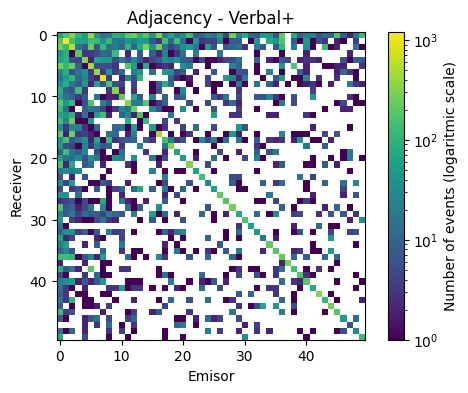

In [10]:

A = matrices[(3, 105)]
print("Dimensions:", A.shape)
print("Connections:", A.nnz)
print("Events:", A.sum())
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
plt.figure(figsize=(6, 4))
plt.imshow(A.toarray(), cmap="viridis", norm=LogNorm(vmin=1, vmax=A.toarray().max()), interpolation="nearest")
plt.colorbar(label="Number of events (logaritmic scale)")
plt.title("Adjacency - Verbal+")
plt.xlabel("Emisor")
plt.ylabel("Receiver")

plt.show()

## Normal transformation

In [11]:
N = len(countries_top)
T = len(months)
K = len(layers)
index_countries = {country: i for i, country in enumerate(countries_top)}
index_months = {month: i for i, month in enumerate(months)}
index_layers = {layer: i for i, layer in enumerate(layers)}
top50_network["month"] = pd.to_datetime(top50_network["month"])
top50_network["i"] = top50_network["origin"].map(index_countries)
top50_network["j"] = top50_network["destination"].map(index_countries)
top50_network["t"] = top50_network["month"].map(index_months)
top50_network["k"] = top50_network["layer"].map(index_layers)
assert top50_network[["i", "j", "t", "k"]].notna().all().all()
Y_raw = np.zeros((K, N, N, T), dtype=np.float64)
Y_raw[
    top50_network["k"].to_numpy(dtype=int),
    top50_network["i"].to_numpy(dtype=int),
    top50_network["j"].to_numpy(dtype=int),
    top50_network["t"].to_numpy(dtype=int)
] = top50_network["weight"].to_numpy()
ranks = rankdata(Y_raw, axis=3, method="average")
probabilities = (ranks - 0.5) / T
Y_normal = norm.ppf(probabilities)
print("Original tensor shape:", Y_raw.shape)
print("Transformed tensor shape:", Y_normal.shape)
print("Countries:", N)
print("Months:", T)
print("Layers:", K)
np.savez_compressed("ICEWS_top50_month_normal.npz",Y_normal=Y_normal)
metadata_normal = {"countries": countries_top, "months": months.strftime("%Y-%m-%d").tolist(),
    "layers": layers, "transformation": "Normal quantile transformation", "dimensions": list(Y_normal.shape)}
with open("ICEWS_top50_month_normal_metadata.json","w",encoding="utf-8") as f:
    json.dump(metadata_normal, f, ensure_ascii=False, indent=4)

Original tensor shape: (4, 50, 50, 336)
Transformed tensor shape: (4, 50, 50, 336)
Countries: 50
Months: 336
Layers: 4


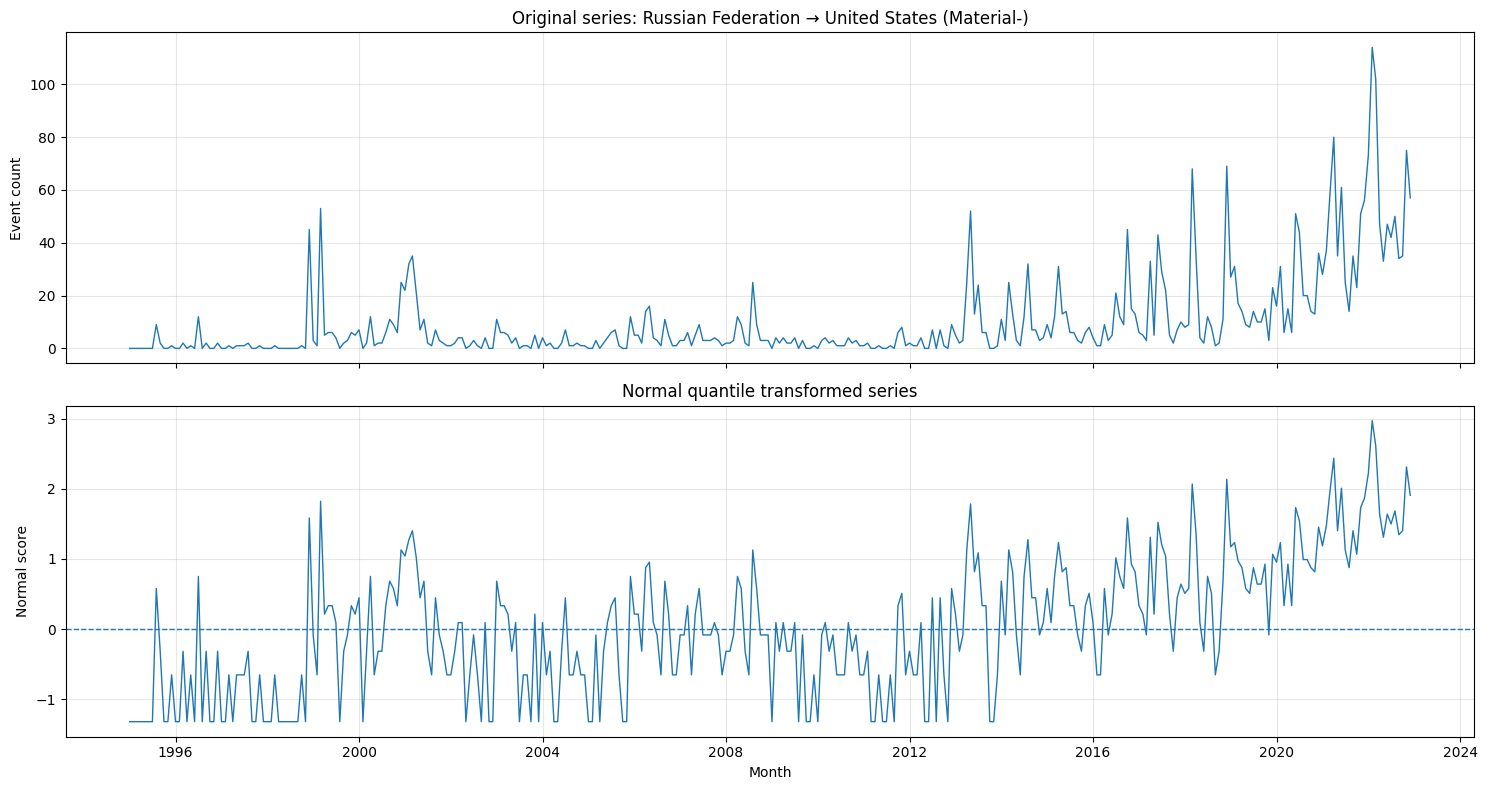

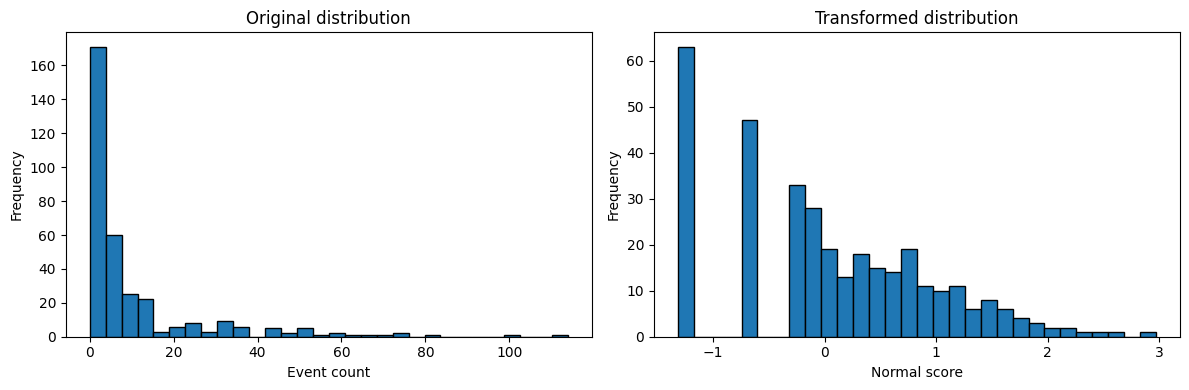

In [12]:

k = 0
i = 1
j = 0
original_series = Y_raw[k, i, j, :]
normal_series = Y_normal[k, i, j, :]
origin = countries_top[i]
destination = countries_top[j]
layer = layers[k]
time_axis = pd.to_datetime(months)
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
axes[0].plot(time_axis, original_series, linewidth=1)
axes[0].set_title(f"Original series: {origin} → {destination} ({layer})")
axes[0].set_ylabel("Event count")
axes[0].grid(alpha=0.3)
axes[1].plot(time_axis, normal_series, linewidth=1)
axes[1].axhline(0, linestyle="--", linewidth=1)
axes[1].set_title("Normal quantile transformed series")
axes[1].set_ylabel("Normal score")
axes[1].set_xlabel("Month")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(original_series, bins=30, edgecolor="black")
axes[0].set_title("Original distribution")
axes[0].set_xlabel("Event count")
axes[0].set_ylabel("Frequency")
axes[1].hist(normal_series, bins=30, edgecolor="black")
axes[1].set_title("Transformed distribution")
axes[1].set_xlabel("Normal score")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

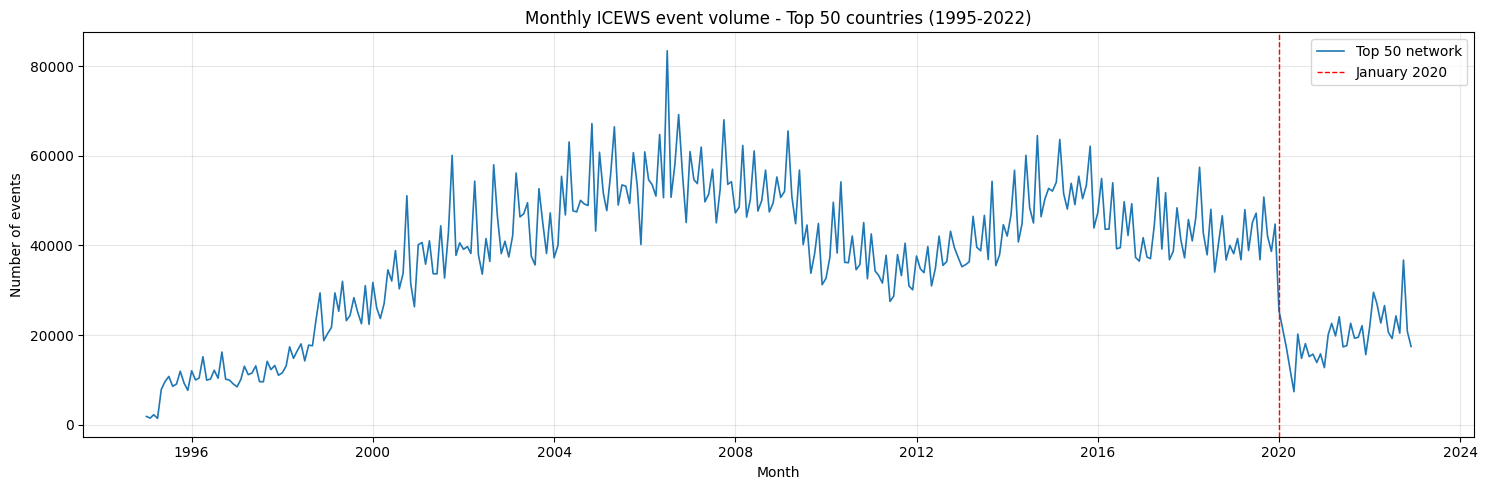

Total events: 12407763
Number of months: 336
Months without events: 0
Average monthly events: 36927.87


In [13]:

top50_monthly_events = (top50_network.groupby("month")["weight"].sum().reindex(months, fill_value=0))
plt.figure(figsize=(15, 5))
plt.plot(top50_monthly_events.index,top50_monthly_events.values,linewidth=1.2,label="Top 50 network")
plt.axvline(pd.Timestamp("2020-01-01"),color="red",linestyle="--",linewidth=1,label="January 2020")
plt.title("Monthly ICEWS event volume - Top 50 countries (1995-2022)")
plt.xlabel("Month")
plt.ylabel("Number of events")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Total events:", top50_monthly_events.sum())
print("Number of months:", len(top50_monthly_events))
print("Months without events:", (top50_monthly_events == 0).sum())
print("Average monthly events:", round(top50_monthly_events.mean(), 2))